# Customer Segmentation using K-Means Clustering

##1. Install Required Libraries

In [ ]:
# Install necessary libraries
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl scipy joblib --quiet

##2. Import Libraries and Configure Visualization

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib # Import matplotlib directly for version
import seaborn as sns
import sklearn # Import sklearn directly for version
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import joblib
import scipy # Import scipy directly for version
import os

# Display installed library versions
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}") # Corrected to sklearn.__version__
print(f"SciPy version: {scipy.__version__}") # Corrected to scipy.__version__

# Configure a consistent visualisation style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("Consistent visualization style configured.")

Pandas version: 2.2.3
NumPy version: 2.1.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2
Scikit-learn version: 1.6.1
SciPy version: 1.16.3
Consistent visualization style configured.


##3. Extract ZIP File and Load Dataset

In [ ]:
# 1. Check whether the uploaded ZIP file exists in /content
zip_file_path = '/content/online+retail+ii.zip'
if os.path.exists(zip_file_path):
    print(f"ZIP file '{zip_file_path}' found.")
else:
    print(f"Error: ZIP file '{zip_file_path}' not found. Please ensure it's uploaded.")

# 3. Extract the ZIP file into a suitable directory
extraction_path = '/content/retail_data'
os.makedirs(extraction_path, exist_ok=True)

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)
print(f"ZIP file extracted to '{extraction_path}'.")

# 4. List all extracted files
extracted_files = os.listdir(extraction_path)
print("Extracted files:")
for file in extracted_files:
    print(f"- {file}")

# 5. Identify the Excel or CSV files containing transaction records
excel_files = [f for f in extracted_files if f.endswith(('.xlsx', '.xls'))]
csv_files = [f for f in extracted_files if f.endswith('.csv')]

if not excel_files and not csv_files:
    raise FileNotFoundError("No Excel or CSV files found in the extracted archive.")

# 6. Load the dataset into a Pandas DataFrame
# 7. If the dataset is stored across multiple Excel sheets, inspect and load the appropriate sheets.
# 8. If both years are available, combine the transaction data into one DataFrame while retaining the original columns.

all_df = []
if excel_files:
    print(f"Attempting to load Excel files: {excel_files}")
    for excel_file in excel_files:
        file_path = os.path.join(extraction_path, excel_file)
        xls = pd.ExcelFile(file_path)
        sheet_names = xls.sheet_names
        print(f"Sheets found in {excel_file}: {sheet_names}")
        for sheet_name in sheet_names:
            print(f"Loading sheet: {sheet_name}")
            df = pd.read_excel(xls, sheet_name=sheet_name)
            df['SourceFile'] = excel_file # Keep track of original file/sheet if needed
            df['SourceSheet'] = sheet_name
            all_df.append(df)
elif csv_files:
    print(f"Attempting to load CSV files: {csv_files}")
    for csv_file in csv_files:
        file_path = os.path.join(extraction_path, csv_file)
        print(f"Loading CSV file: {csv_file}")
        df = pd.read_csv(file_path)
        df['SourceFile'] = csv_file # Keep track of original file
        all_df.append(df)

if not all_df:
    raise ValueError("No dataframes were loaded from the extracted files.")

df_raw = pd.concat(all_df, ignore_index=True)
print(f"Successfully loaded and combined {len(all_df)} dataframes into a single DataFrame with {len(df_raw)} rows.")

# 9. Display the first five rows, last five rows and a random sample of records.
print("\nFirst 5 rows:")
display(df_raw.head())

print("\nLast 5 rows:")
display(df_raw.tail())

print("\nRandom 5 rows:")
display(df_raw.sample(5))

# 10. Display the shape, column names, data types, memory usage and basic statistical summary.
print("\nDataFrame Shape:", df_raw.shape)
print("\nColumn Names:", df_raw.columns.tolist())
print("\nData Types:")
display(df_raw.info())

print("\nMemory Usage:")
display(df_raw.memory_usage(deep=True))

print("\nBasic Statistical Summary:")
display(df_raw.describe(include='all'))

ZIP file '/content/online+retail+ii.zip' found.
ZIP file extracted to '/content/retail_data'.
Extracted files:
- online_retail_II.xlsx
Attempting to load Excel files: ['online_retail_II.xlsx']
Sheets found in online_retail_II.xlsx: ['Year 2009-2010', 'Year 2010-2011']
Loading sheet: Year 2009-2010
Loading sheet: Year 2010-2011
Successfully loaded and combined 2 dataframes into a single DataFrame with 1067371 rows.

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceFile,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010



Last 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceFile,SourceSheet
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,online_retail_II.xlsx,Year 2010-2011
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,online_retail_II.xlsx,Year 2010-2011
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,online_retail_II.xlsx,Year 2010-2011
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,online_retail_II.xlsx,Year 2010-2011
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France,online_retail_II.xlsx,Year 2010-2011



Random 5 rows:


...

None


Memory Usage:


,0
Index,132
Invoice,38815356
StockCode,40974820
Description,80585578
Quantity,8538968
InvoiceDate,8538968
Price,8538968
Customer ID,8538968
Country,66618497
SourceFile,74715970



Basic Statistical Summary:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceFile,SourceSheet
count,1067371.0,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371,1067371,1067371
unique,53628.0,5305,5698,NaN,NaN,NaN,NaN,43,1,2
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom,online_retail_II.xlsx,Year 2010-2011
freq,1350.0,5829,5918,NaN,NaN,NaN,NaN,981330,1067371,541910
mean,NaN,NaN,NaN,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504,NaN,NaN,NaN
min,NaN,NaN,NaN,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000,NaN,NaN,NaN
max,NaN,NaN,NaN,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000,NaN,NaN,NaN


##4. Dataset Overview and Initial Data Quality Analysis

In [ ]:
# 1. Total transaction rows and columns
print("\n--- Dataset Overview ---")
print(f"Total transaction rows: {df_raw.shape[0]}")
print(f"Total columns: {df_raw.shape[1]}")

# 2. Unique customers, invoices, and products
# Drop rows where CustomerID is NaN before counting unique customers, as per usual practice for customer-centric analysis
# However, for initial analysis, we might want to see the count before considering NaNs if the problem statement requires it.
# For now, let's count unique CustomerIDs including NaNs to get the full picture, and then identify how many are missing.

unique_customers = df_raw['Customer ID'].nunique(dropna=False) # Corrected column name
unique_invoices = df_raw['Invoice'].nunique()
unique_products = df_raw['StockCode'].nunique()

print(f"Unique customers (including NaN CustomerID): {unique_customers}")
print(f"Unique invoices: {unique_invoices}")
print(f"Unique products: {unique_products}")

# 3. Countries represented
countries = df_raw['Country'].nunique()
print(f"Countries represented: {countries}")
print("Top 10 Countries by transactions:\n")
display(df_raw['Country'].value_counts().head(10).to_frame())

# 4. Missing values in every column
print("\n--- Missing Values ---")
missing_values = df_raw.isnull().sum()
missing_percentage = (df_raw.isnull().sum() / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percentage': missing_percentage})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

# 5. Duplicate records
duplicates = df_raw.duplicated().sum()
print(f"\n--- Duplicate Records ---")
print(f"Total duplicate rows: {duplicates}")

# 6. Numerical and categorical features
numerical_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_raw.select_dtypes(include=['object', 'category']).columns.tolist()

print("\n--- Feature Types ---")
print(f"Numerical features: {numerical_cols}")
print(f"Categorical features: {categorical_cols}")

# 7. Earliest and latest invoice dates
# First ensure InvoiceDate is datetime type for this check
# This will be properly handled in Step 5, but for initial analysis we can try to convert.

try:
    # Try to convert, but make a copy to avoid SettingWithCopyWarning if df_raw is modified later
    df_raw_dates = df_raw.copy()
    df_raw_dates['InvoiceDate'] = pd.to_datetime(df_raw_dates['InvoiceDate'])
    earliest_date = df_raw_dates['InvoiceDate'].min()
    latest_date = df_raw_dates['InvoiceDate'].max()
    print(f"\n--- Invoice Dates ---")
    print(f"Earliest invoice date: {earliest_date}")
    print(f"Latest invoice date: {latest_date}")
except Exception as e:
    print(f"\nCould not determine earliest/latest invoice dates due to error: {e}")
    print("InvoiceDate column might not be in a standard datetime format or requires cleaning.")


print("\nInitial dataset analysis complete. Details displayed above.")


--- Dataset Overview ---
Total transaction rows: 1067371
Total columns: 10
Unique customers (including NaN CustomerID): 5943
Unique invoices: 53628
Unique products: 5305
Countries represented: 43
Top 10 Countries by transactions:



,count
Country,
United Kingdom,981330
EIRE,17866
Germany,17624
France,14330
Netherlands,5140
Spain,3811
Switzerland,3189
Belgium,3123
Portugal,2620



--- Missing Values ---


,Missing Count,Missing Percentage
Customer ID,243007,22.766873
Description,4382,0.410541



--- Duplicate Records ---
Total duplicate rows: 12133

--- Feature Types ---
Numerical features: ['Quantity', 'Price', 'Customer ID']
Categorical features: ['Invoice', 'StockCode', 'Description', 'Country', 'SourceFile', 'SourceSheet']

--- Invoice Dates ---
Earliest invoice date: 2009-12-01 07:45:00
Latest invoice date: 2011-12-09 12:50:00

Initial dataset analysis complete. Details displayed above.


##5. Missing Value Analysis and Handling


--- Missing Value Analysis ---
Missing values before handling:


,Missing Count,Missing Percentage
Customer ID,243007,22.766873
Description,4382,0.410541


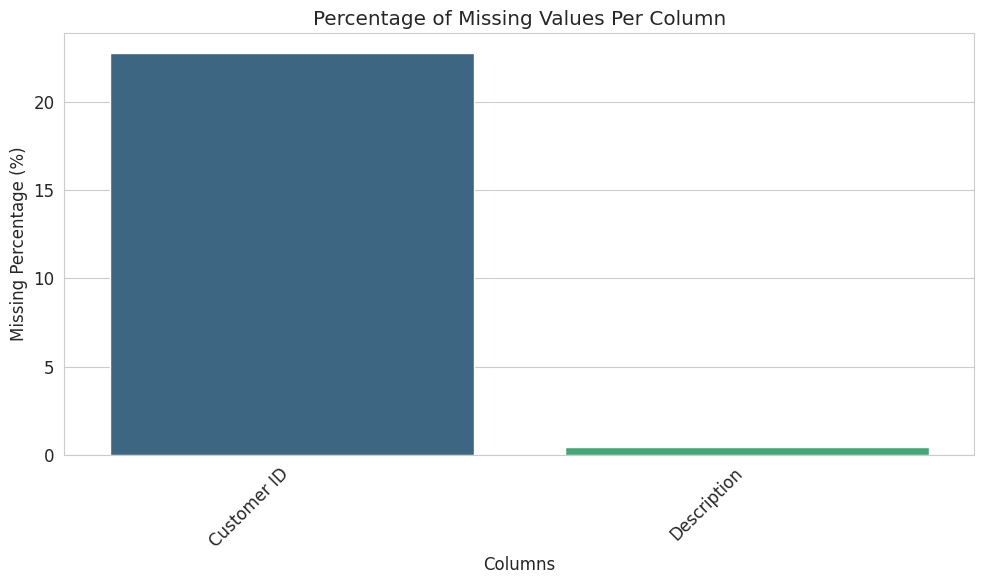

Columns identified with missing values: ['Customer ID', 'Description']
Initial number of rows in df_cleaned: 1067371

--- Handling Missing CustomerID ---
Number of rows with missing 'Customer ID' before dropping: 243007
Number of rows dropped due to missing 'Customer ID': 243007
Remaining rows after dropping missing 'Customer ID': 824364
Explanation: Records without a 'Customer ID' cannot be attributed to a specific customer, making them unsuitable for customer-level segmentation. Therefore, these records are removed to ensure that all remaining transactions can be linked to a unique customer.

--- Handling Missing Description ---
Number of rows with missing 'Description' before handling: 0
Missing 'Description' values filled with 'UNKNOWN_DESCRIPTION'.
Remaining rows after handling missing 'Description': 824364
Explanation: Transactions with missing product descriptions are still valid purchases. Filling missing descriptions with 'UNKNOWN_DESCRIPTION' allows us to retain these transac

,Missing Count,Missing Percentage


Step 4: Missing-value analysis complete. Missing 'Customer ID' rows were removed, and 'Description' NaNs were filled.


In [ ]:
# Make a copy of the raw DataFrame to perform cleaning steps, preserving the original raw data
df_cleaned = df_raw.copy()

print("--- Missing Value Analysis ---")

# 1. Calculate missing values in each column
missing_values = df_cleaned.isnull().sum()

# 2. Display missing-value counts and percentages
missing_percentage = (df_cleaned.isnull().sum() / len(df_cleaned)) * 100
missing_df_step4 = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentage
})

# Filter to show only columns with missing values
missing_df_step4 = missing_df_step4[missing_df_step4['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Missing values before handling:")
display(missing_df_step4)

# 3. Create a missing-value bar chart
if not missing_df_step4.empty:
    plt.figure(figsize=(10, 6))
    # Corrected sns.barplot to avoid FutureWarning
    sns.barplot(x=missing_df_step4.index, y='Missing Percentage', hue=missing_df_step4.index, data=missing_df_step4, palette='viridis', legend=False)
    plt.title('Percentage of Missing Values Per Column')
    plt.xlabel('Columns')
    plt.ylabel('Missing Percentage (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset at this stage for plotting.")

# 4. Identify the columns with missing values
columns_with_missing = missing_df_step4.index.tolist()
print(f"Columns identified with missing values: {columns_with_missing}")

initial_rows = len(df_cleaned)
print(f"Initial number of rows in df_cleaned: {initial_rows}")

# 5. Handle missing CustomerID values by excluding records that cannot be associated with a customer from customer-level segmentation.
# Records without a CustomerID are often not useful for customer segmentation as we cannot track individual customer behavior.
# We will drop these rows. This is a common practice in RFM analysis.
print("\n--- Handling Missing CustomerID ---")
print(f"Number of rows with missing 'Customer ID' before dropping: {df_cleaned['Customer ID'].isnull().sum()}")
df_cleaned.dropna(subset=['Customer ID'], inplace=True)
customers_dropped = initial_rows - len(df_cleaned)
print(f"Number of rows dropped due to missing 'Customer ID': {customers_dropped}")
print(f"Remaining rows after dropping missing 'Customer ID': {len(df_cleaned)}")
print("Explanation: Records without a 'Customer ID' cannot be attributed to a specific customer, making them unsuitable for customer-level segmentation. Therefore, these records are removed to ensure that all remaining transactions can be linked to a unique customer.")

# 6. Handle missing product descriptions appropriately without unnecessarily removing valid transactions.
# Missing descriptions might mean an invalid product code or a data entry error, but the transaction itself might be valid.
# For now, we will fill missing descriptions with a placeholder 'UNKNOWN_DESCRIPTION'.
# This allows us to retain the transaction data for quantity and monetary analysis, even if the product detail is missing.
print("\n--- Handling Missing Description ---")
print(f"Number of rows with missing 'Description' before handling: {df_cleaned['Description'].isnull().sum()}")
df_cleaned['Description'] = df_cleaned['Description'].fillna('UNKNOWN_DESCRIPTION') # Fix FutureWarning for inplace=True
print("Missing 'Description' values filled with 'UNKNOWN_DESCRIPTION'.")
print(f"Remaining rows after handling missing 'Description': {len(df_cleaned)}")
print("Explanation: Transactions with missing product descriptions are still valid purchases. Filling missing descriptions with 'UNKNOWN_DESCRIPTION' allows us to retain these transactions for overall spending and frequency calculations without losing valuable sales data, while clearly marking products with absent descriptions.")

# Final check of missing values after handling
print("\n--- Missing Values After Handling ---")
final_missing_values = df_cleaned.isnull().sum()
final_missing_percentage = (df_cleaned.isnull().sum() / len(df_cleaned)) * 100
final_missing_df = pd.DataFrame({
    'Missing Count': final_missing_values,
    'Missing Percentage': final_missing_percentage
})
display(final_missing_df[final_missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

print("Step 4: Missing-value analysis complete. Missing 'Customer ID' rows were removed, and 'Description' NaNs were filled.")

##6. Duplicate Removal and Invalid Transaction Handling


In [ ]:
print("\n--- Duplicate and Invalid Transaction Handling ---")

original_rows_count = len(df_cleaned)
print(f"Initial number of rows for Step 5: {original_rows_count}")

# 1. Identify exact duplicate rows.
print(f"\nNumber of exact duplicate rows identified: {df_cleaned.duplicated().sum()}")
duplicate_rows = df_cleaned[df_cleaned.duplicated(keep=False)] # keep=False marks all duplicates as True
if not duplicate_rows.empty:
    print("Sample of duplicate rows (first 5):")
    display(duplicate_rows.sort_values(by=['Invoice', 'StockCode', 'Description']).head())

# 2. Remove exact duplicates.
df_cleaned.drop_duplicates(inplace=True)
removed_duplicates_count = original_rows_count - len(df_cleaned)
print(f"Number of exact duplicate rows removed: {removed_duplicates_count}")
print(f"Remaining rows after removing duplicates: {len(df_cleaned)}")
print("Explanation: Exact duplicate rows often indicate data entry errors or repeated records without new information. Removing them ensures that each transaction is counted only once, preventing skewed analysis of frequency and monetary values.")

# Update original_rows_count for the next step
current_rows_count = len(df_cleaned)

# 3. Convert InvoiceDate to datetime.
print("\n--- Data Type Conversion ---")
print(f"InvoiceDate current dtype: {df_cleaned['InvoiceDate'].dtype}")
df_cleaned['InvoiceDate'] = pd.to_datetime(df_cleaned['InvoiceDate'])
print(f"InvoiceDate new dtype: {df_cleaned['InvoiceDate'].dtype}")
print("Explanation: Converting 'InvoiceDate' to datetime objects is crucial for time-series analysis, calculating recency, and filtering data by date range.")

# 4. Convert relevant numerical columns to suitable numeric data types.
# 'Quantity' and 'Price' (UnitPrice in problem description but 'Price' in df_raw.describe() output) are already numerical, but let's ensure.
print(f"Quantity current dtype: {df_cleaned['Quantity'].dtype}")
print(f"Price current dtype: {df_cleaned['Price'].dtype}")

df_cleaned['Quantity'] = pd.to_numeric(df_cleaned['Quantity'], errors='coerce')
df_cleaned['Price'] = pd.to_numeric(df_cleaned['Price'], errors='coerce')

# Check if any coercions resulted in NaNs
coerced_nans_quantity = df_cleaned['Quantity'].isnull().sum()
coerced_nans_price = df_cleaned['Price'].isnull().sum()

if coerced_nans_quantity > 0:
    print(f"Warning: {coerced_nans_quantity} NaNs introduced in 'Quantity' during numeric conversion. These will be handled with other invalid values.")
if coerced_nans_price > 0:
    print(f"Warning: {coerced_nans_price} NaNs introduced in 'Price' during numeric conversion. These will be handled with other invalid values.")

print("Explanation: Ensuring numerical columns are of appropriate data types is fundamental for mathematical operations and accurate statistical analysis. 'errors=\'coerce\'' handles non-numeric entries by turning them into NaN, which will be cleaned subsequently.")

# 5. Identify cancelled invoices, including invoice numbers that begin with C where applicable.
print("\n--- Identifying Cancelled and Invalid Transactions ---")
cancelled_transactions = df_cleaned[df_cleaned['Invoice'].astype(str).str.startswith('C', na=False)]
print(f"Number of cancelled transactions (Invoice starting with 'C'): {len(cancelled_transactions)}")
print("Explanation: Transactions with invoice numbers starting with 'C' typically indicate cancellations or returns. These are important to identify as they represent reversed sales and should be handled separately from valid purchases.")

# 6. Identify negative and zero quantities.
negative_quantity_transactions = df_cleaned[df_cleaned['Quantity'] < 0]
zero_quantity_transactions = df_cleaned[df_cleaned['Quantity'] == 0]
print(f"Number of transactions with negative Quantity: {len(negative_quantity_transactions)}")
print(f"Number of transactions with zero Quantity: {len(zero_quantity_transactions)}")
print("Explanation: Negative quantities typically indicate returns (which overlap with 'C' invoices), and zero quantities might represent free samples, data errors, or incomplete transactions. For customer segmentation based on purchase behavior, only positive quantities representing actual purchases are relevant.")

# 7. Identify zero or negative unit prices.
zero_price_transactions = df_cleaned[df_cleaned['Price'] == 0]
negative_price_transactions = df_cleaned[df_cleaned['Price'] < 0]
print(f"Number of transactions with zero UnitPrice: {len(zero_price_transactions)}")
print(f"Number of transactions with negative UnitPrice: {len(negative_price_transactions)}")
print("Explanation: Products with zero or negative unit prices do not contribute to revenue and are often indicative of data errors, promotional items, or other non-sales events. For monetary calculations, these transactions are considered invalid purchases.")

# 8. Examine unusual values and potential outliers.
# This step is more about observation during the above checks.
print("Unusual values are identified through checks for negative/zero quantities and prices. Further outlier examination will be done during EDA on engineered features.")

# 9. Separate cancelled transactions and invalid transactions from valid sales.
# We will define valid sales as having positive Quantity and positive Price, and not being a cancelled invoice (not starting with 'C').
# Also exclude rows where Quantity or Price became NaN due to 'errors=coerce' during type conversion.

# First, identify actual cancelled transactions (usually negative quantity and invoice starts with 'C')
cancelled_invoices_mask = df_cleaned['Invoice'].astype(str).str.startswith('C', na=False)

# Valid transactions should have positive Quantity and Price and not be cancelled
valid_transactions_mask = (
    (df_cleaned['Quantity'] > 0) &
    (df_cleaned['Price'] > 0) &
    (~cancelled_invoices_mask) &
    (df_cleaned['Quantity'].notnull()) &
    (df_cleaned['Price'].notnull())
)

df_valid_sales = df_cleaned[valid_transactions_mask].copy()
df_invalid_transactions = df_cleaned[~valid_transactions_mask].copy()

print(f"\nNumber of valid sales transactions: {len(df_valid_sales)}")
print(f"Number of invalid/cancelled transactions: {len(df_invalid_transactions)}")
print("Explanation: Separating valid sales from cancelled or invalid transactions is critical to build a reliable customer segmentation model. We want to analyze actual purchasing behavior, not returns or data anomalies. 'df_valid_sales' will be our primary dataset for further analysis.")

# 10. Create a cleaned dataset containing valid purchase transactions for the primary spending analysis.
# df_valid_sales is this dataset.

# Preserve a record of the original row count, removed rows and remaining rows at each stage.
print("\n--- Cleaning Summary ---")
rows_after_duplicates = current_rows_count
rows_after_missing_customer_id = original_rows_count + removed_duplicates_count # The definition of original_rows_count in step 5 is AFTER missing customer ID handling

total_rows_at_start = len(df_raw)
print(f"Total initial rows (df_raw): {total_rows_at_start}")
print(f"Rows after dropping missing Customer ID: {rows_after_missing_customer_id}")
print(f"Rows after removing exact duplicates: {rows_after_duplicates}")
print(f"Rows after separating valid sales: {len(df_valid_sales)}")
print(f"Total rows removed during Step 5: {rows_after_duplicates - len(df_valid_sales)}")

print("Step 5: Duplicate and invalid transaction handling complete. A 'df_valid_sales' DataFrame has been created for primary analysis.")

# Display summary of df_valid_sales
print("\nSummary of df_valid_sales:")
display(df_valid_sales.head())
display(df_valid_sales.info())
display(df_valid_sales.select_dtypes(include=np.number).describe()) # Fix FutureWarning for numeric_only


--- Duplicate and Invalid Transaction Handling ---
Initial number of rows for Step 5: 812368

Number of exact duplicate rows identified: 0
Number of exact duplicate rows removed: 0
Remaining rows after removing duplicates: 812368
Explanation: Exact duplicate rows often indicate data entry errors or repeated records without new information. Removing them ensures that each transaction is counted only once, preventing skewed analysis of frequency and monetary values.

--- Data Type Conversion ---
InvoiceDate current dtype: datetime64[ns]
InvoiceDate new dtype: datetime64[ns]
Explanation: Converting 'InvoiceDate' to datetime objects is crucial for time-series analysis, calculating recency, and filtering data by date range.
Quantity current dtype: int64
Price current dtype: float64
Explanation: Ensuring numerical columns are of appropriate data types is fundamental for mathematical operations and accurate statistical analysis. 'errors='coerce'' handles non-numeric entries by turning them i

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceFile,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,online_retail_II.xlsx,Year 2009-2010


<class 'pandas.core.frame.DataFrame'>
Index: 793609 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      793609 non-null  object        
 1   StockCode    793609 non-null  object        
 2   Description  793609 non-null  object        
 3   Quantity     793609 non-null  int64         
 4   InvoiceDate  793609 non-null  datetime64[ns]
 5   Price        793609 non-null  float64       
 6   Customer ID  793609 non-null  float64       
 7   Country      793609 non-null  object        
 8   SourceFile   793609 non-null  object        
 9   SourceSheet  793609 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 66.6+ MB


None

,Quantity,Price,Customer ID
count,793609.000000,793609.000000,793609.000000
mean,13.446900,3.216821,15325.072507
std,144.693151,29.416465,1697.397406
min,1.000000,0.001000,12346.000000
25%,2.000000,1.250000,13975.000000
50%,6.000000,1.950000,15255.000000
75%,12.000000,3.750000,16797.000000
max,80995.000000,10953.500000,18287.000000


##7. Final Data Quality Verification


In [ ]:
print("\n--- Final Data Quality Verification ---")

# 1. Check for missing values.
missing_values_final = df_valid_sales.isnull().sum()
missing_percentage_final = (df_valid_sales.isnull().sum() / len(df_valid_sales)) * 100
missing_df_final = pd.DataFrame({
    'Missing Count': missing_values_final,
    'Missing Percentage': missing_percentage_final
})
display(missing_df_final[missing_df_final['Missing Count'] > 0])
print("Check for missing values: All critical columns should now have 0 missing values.")

# 2. Check for duplicate transactions.
duplicates_final = df_valid_sales.duplicated().sum()
print(f"Number of duplicate rows in df_valid_sales: {duplicates_final}")
if duplicates_final == 0:
    print("Check for duplicate transactions: No duplicate rows found.")
else:
    print("Warning: Duplicate rows still exist.")

# 3. Check data types.
print("\nData Types in df_valid_sales:")
display(df_valid_sales.info())
print("Check data types: 'InvoiceDate' should be datetime, 'Quantity' and 'Price' should be numeric.")

# 4. Check invalid numerical values (Quantity > 0, Price > 0).
invalid_qty = df_valid_sales[df_valid_sales['Quantity'] <= 0].shape[0]
invalid_price = df_valid_sales[df_valid_sales['Price'] <= 0].shape[0]
print(f"\nNumber of records with Quantity <= 0: {invalid_qty}")
print(f"Number of records with Price <= 0: {invalid_price}")
if invalid_qty == 0 and invalid_price == 0:
    print("Check invalid numerical values: All Quantity and Price values are positive.")
else:
    print("Warning: Invalid Quantity or Price values found.")

# 5. Check invoice dates.
earliest_date_final = df_valid_sales['InvoiceDate'].min()
latest_date_final = df_valid_sales['InvoiceDate'].max()
print(f"\nEarliest InvoiceDate: {earliest_date_final}")
print(f"Latest InvoiceDate: {latest_date_final}")
print("Check invoice dates: Dates appear to be in a valid range and format.")

# 6. Check the consistency of customer IDs.
# Ensure Customer IDs are not NaN and are of consistent type (float as per data, but conceptual consistency).
print(f"\nUnique Customer IDs: {df_valid_sales['Customer ID'].nunique()}")
print(f"Customer ID column dtype: {df_valid_sales['Customer ID'].dtype}")
if df_valid_sales['Customer ID'].isnull().sum() == 0:
    print("Check Customer ID consistency: No missing Customer IDs.")
else:
    print("Warning: Missing Customer IDs found.")

# 7. Verify the final cleaned dataset shape.
final_shape = df_valid_sales.shape
print(f"\nFinal shape of df_valid_sales (rows, columns): {final_shape}")
print("Final dataset shape verified.")

# Display a data quality summary table before moving to feature engineering.
data_quality_summary = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values (Total)',
        'Duplicate Rows',
        'Negative/Zero Quantity',
        'Negative/Zero Price',
        'Unique Customer IDs'
    ],
    'Value': [
        final_shape[0],
        final_shape[1],
        df_valid_sales.isnull().sum().sum(),
        duplicates_final,
        invalid_qty,
        invalid_price,
        df_valid_sales['Customer ID'].nunique()
    ]
})
print("\n--- Data Quality Summary (df_valid_sales) ---")
display(data_quality_summary)

print("Step 6: Final data quality verification complete. The dataset is now clean and ready for feature engineering.")


--- Final Data Quality Verification ---


,Missing Count,Missing Percentage


Check for missing values: All critical columns should now have 0 missing values.
Number of duplicate rows in df_valid_sales: 0
Check for duplicate transactions: No duplicate rows found.

Data Types in df_valid_sales:
<class 'pandas.core.frame.DataFrame'>
Index: 793609 entries, 0 to 1067370
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      793609 non-null  object        
 1   StockCode    793609 non-null  object        
 2   Description  793609 non-null  object        
 3   Quantity     793609 non-null  int64         
 4   InvoiceDate  793609 non-null  datetime64[ns]
 5   Price        793609 non-null  float64       
 6   Customer ID  793609 non-null  float64       
 7   Country      793609 non-null  object        
 8   SourceFile   793609 non-null  object        
 9   SourceSheet  793609 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 66.

None

Check data types: 'InvoiceDate' should be datetime, 'Quantity' and 'Price' should be numeric.

Number of records with Quantity <= 0: 0
Number of records with Price <= 0: 0
Check invalid numerical values: All Quantity and Price values are positive.

Earliest InvoiceDate: 2009-12-01 07:45:00
Latest InvoiceDate: 2011-12-09 12:50:00
Check invoice dates: Dates appear to be in a valid range and format.

Unique Customer IDs: 5878
Customer ID column dtype: float64
Check Customer ID consistency: No missing Customer IDs.

Final shape of df_valid_sales (rows, columns): (793609, 10)
Final dataset shape verified.

--- Data Quality Summary (df_valid_sales) ---


,Metric,Value
0,Total Rows,793609
1,Total Columns,10
2,Missing Values (Total),0
3,Duplicate Rows,0
4,Negative/Zero Quantity,0
5,Negative/Zero Price,0
6,Unique Customer IDs,5878


Step 6: Final data quality verification complete. The dataset is now clean and ready for feature engineering.


##8. RFM Feature Engineering (Recency, Frequency, Monetary)


In [ ]:
# Calculate Recency, Frequency, and Monetary (RFM) values

print("\n--- Calculating RFM values ---")

# 1. Determine a snapshot date (e.g., one day after the last transaction date in the dataset)
# This ensures that all transactions are included in the 'Recency' calculation.
snapshot_date = df_valid_sales['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Snapshot date for RFM calculation: {snapshot_date}")

# Group by Customer ID and calculate RFM metrics
rfm_df = df_valid_sales.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda date: (snapshot_date - date.max()).days), # Days since last purchase
    Frequency=('Invoice', 'nunique'), # Number of unique invoices/transactions
    Monetary=('Price', lambda price: (price * df_valid_sales.loc[price.index, 'Quantity']).sum()) # Total spending
).reset_index()

# Ensure Customer ID is an integer type for cleaner output and consistency, if it was float due to NaNs earlier
rfm_df['Customer ID'] = rfm_df['Customer ID'].astype(int)

print("RFM calculation complete. Displaying first 5 rows of RFM DataFrame:")
display(rfm_df.head())

print("\nDescriptive statistics for RFM DataFrame:")
display(rfm_df.describe())

print("\nExplanation of RFM metrics:")
print("- **Recency**: Number of days since the customer's last purchase. Lower values indicate more recent activity.")
print("- **Frequency**: Total number of unique purchases made by the customer. Higher values indicate more frequent purchasing.")
print("- **Monetary**: Total revenue generated by the customer. Higher values indicate more spending.")
print("Step 7: RFM value calculation complete.")


--- Calculating RFM values ---
Snapshot date for RFM calculation: 2011-12-10 12:50:00
RFM calculation complete. Displaying first 5 rows of RFM DataFrame:


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,5633.32
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40



Descriptive statistics for RFM DataFrame:


,Customer ID,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,15315.313542,201.331916,6.289384,3008.754787
std,1715.572666,209.338707,13.009406,14731.924115
min,12346.000000,1.000000,1.000000,2.950000
25%,13833.250000,26.000000,1.000000,345.115000
50%,15314.500000,96.000000,3.000000,887.390000
75%,16797.750000,380.000000,7.000000,2298.005000
max,18287.000000,739.000000,398.000000,608821.650000



Explanation of RFM metrics:
- **Recency**: Number of days since the customer's last purchase. Lower values indicate more recent activity.
- **Frequency**: Total number of unique purchases made by the customer. Higher values indicate more frequent purchasing.
- **Monetary**: Total revenue generated by the customer. Higher values indicate more spending.
Step 7: RFM value calculation complete.


##9. RFM Distribution Analysis and Skewness Calculation



--- Original RFM Feature Distributions and Skewness ---


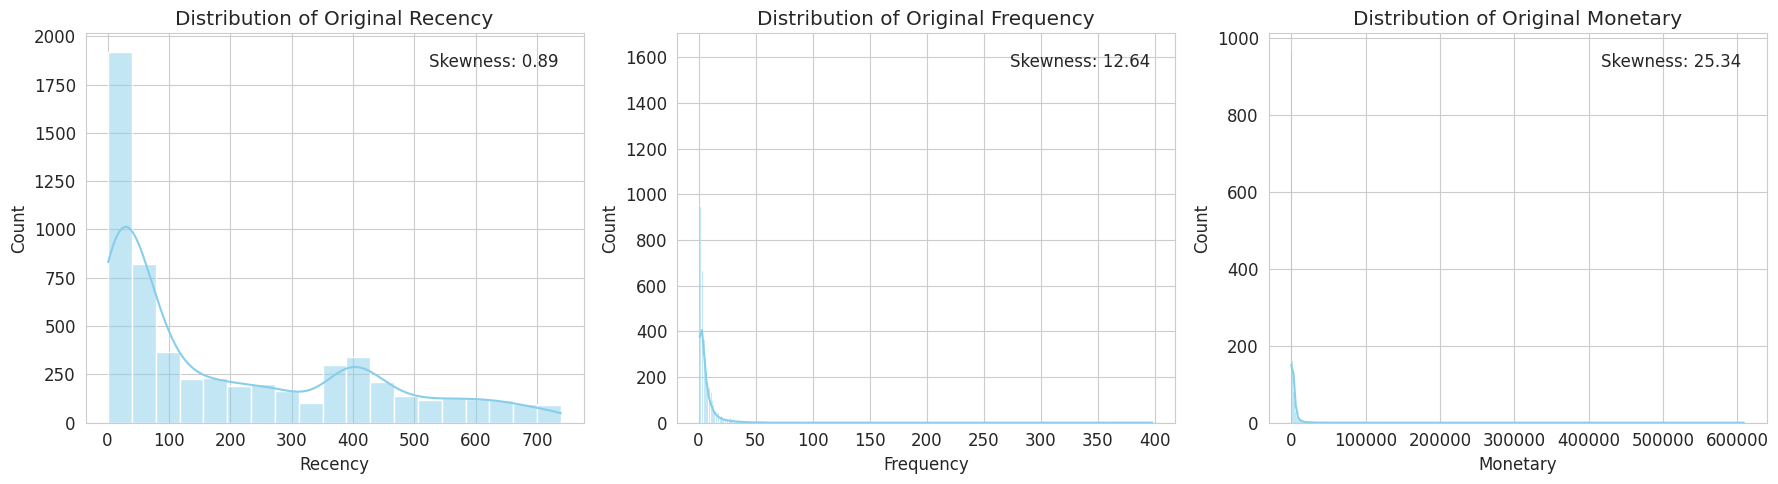

Skewness before transformation:
  Recency: 0.89
  Frequency: 12.64
  Monetary: 25.34
Explanation: The histograms clearly show that 'Recency', 'Frequency', and 'Monetary' features are highly right-skewed. This is common in customer data, where a small number of customers are highly frequent/monetary, and many are infrequent/low-monetary. Skewness can negatively impact distance-based clustering algorithms.


In [ ]:
# 1. Plot histograms of the original RFM features
# 2. Calculate and display the skewness values before transformation

print("\n--- Original RFM Feature Distributions and Skewness ---")

# Create a figure with subplots for histograms
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

rfm_features = ['Recency', 'Frequency', 'Monetary']
original_skewness = {}

for i, feature in enumerate(rfm_features):
    sns.histplot(rfm_df[feature], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of Original {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Count')
    original_skewness[feature] = rfm_df[feature].skew()
    axes[i].text(0.95, 0.95, f'Skewness: {original_skewness[feature]:.2f}',
                 transform=axes[i].transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right')

plt.tight_layout()
plt.show()

print("Skewness before transformation:")
for feature, skew_val in original_skewness.items():
    print(f"  {feature}: {skew_val:.2f}")

print("Explanation: The histograms clearly show that 'Recency', 'Frequency', and 'Monetary' features are highly right-skewed. This is common in customer data, where a small number of customers are highly frequent/monetary, and many are infrequent/low-monetary. Skewness can negatively impact distance-based clustering algorithms.")

##10. Log Transformation of RFM Features


In [ ]:
# 3. Apply np.log1p() to the appropriate non-negative RFM features, keeping the original columns unchanged.
# Note: np.log1p(x) computes log(1+x), which is suitable for data that might contain zeros.

print("\n--- Applying Log1p Transformation to RFM Features ---")

# Create a copy of the RFM DataFrame for transformation
rfm_log_transformed_df = rfm_df.copy()

# Apply log1p transformation to Recency, Frequency, and Monetary features
for feature in rfm_features:
    # Ensure no negative values before applying log1p, although RFM should already be non-negative
    if (rfm_log_transformed_df[feature] < 0).any():
        print(f"Warning: Negative values found in {feature}. log1p will produce NaNs/errors.")
    rfm_log_transformed_df[feature] = np.log1p(rfm_log_transformed_df[feature])

print("Log1p transformation applied to 'Recency', 'Frequency', and 'Monetary' columns.")
print("Displaying first 5 rows of the transformed RFM DataFrame:")
display(rfm_log_transformed_df.head())


--- Applying Log1p Transformation to RFM Features ---
Log1p transformation applied to 'Recency', 'Frequency', and 'Monetary' columns.
Displaying first 5 rows of the transformed RFM DataFrame:


,Customer ID,Recency,Frequency,Monetary
0,12346,5.789960,2.564949,11.258774
1,12347,1.098612,2.197225,8.636632
2,12348,4.330733,1.791759,7.611051
3,12349,2.995732,1.609438,8.396085
4,12350,5.739793,0.693147,5.815324


##11. Transformed RFM Distribution and Skewness Comparison



--- Transformed RFM Feature Distributions and Skewness Comparison ---


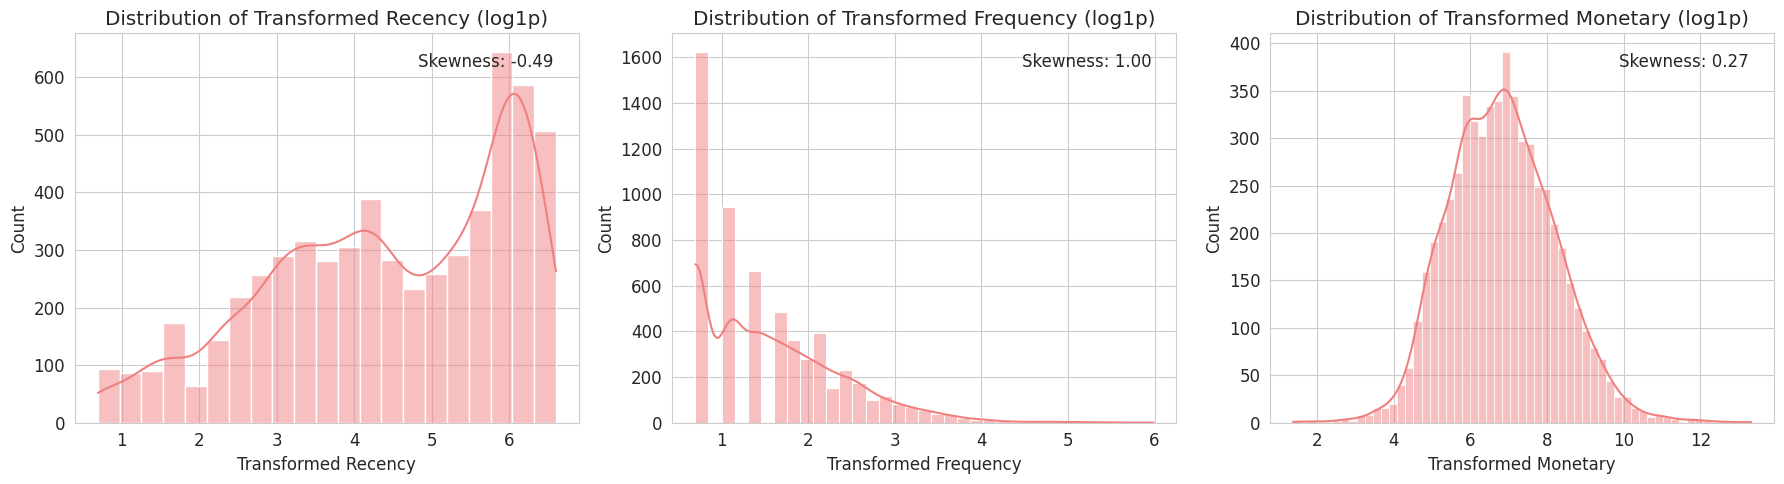

Skewness comparison:
Feature        | Original Skewness | Transformed Skewness
--------------------------------------------------
Recency        | 0.89              | -0.49
Frequency      | 12.64             | 1.00
Monetary       | 25.34             | 0.27
Explanation: After applying the log1p transformation, the distributions of all three RFM features appear much more symmetrical and less skewed. The skewness values have significantly reduced, which is ideal for clustering algorithms that assume normally distributed or less skewed data.


In [ ]:
# 4. Plot histograms after transformation.
# 5. Calculate and compare skewness values before and after transformation.

print("\n--- Transformed RFM Feature Distributions and Skewness Comparison ---")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

transformed_skewness = {}

for i, feature in enumerate(rfm_features):
    sns.histplot(rfm_log_transformed_df[feature], kde=True, ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Distribution of Transformed {feature} (log1p)')
    axes[i].set_xlabel(f'Transformed {feature}')
    axes[i].set_ylabel('Count')
    trans_skew = rfm_log_transformed_df[feature].skew()
    transformed_skewness[feature] = trans_skew
    axes[i].text(0.95, 0.95, f'Skewness: {trans_skew:.2f}',
                 transform=axes[i].transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right')

plt.tight_layout()
plt.show()

print("Skewness comparison:")
print("Feature        | Original Skewness | Transformed Skewness")
print("--------------------------------------------------")
for feature in rfm_features:
    print(f"{feature:<14} | {original_skewness[feature]:<17.2f} | {transformed_skewness[feature]:<.2f}")

print("Explanation: After applying the log1p transformation, the distributions of all three RFM features appear much more symmetrical and less skewed. The skewness values have significantly reduced, which is ideal for clustering algorithms that assume normally distributed or less skewed data.")

##12. RFM Feature Correlation Heatmap



--- Correlation Heatmap of Transformed RFM Features ---


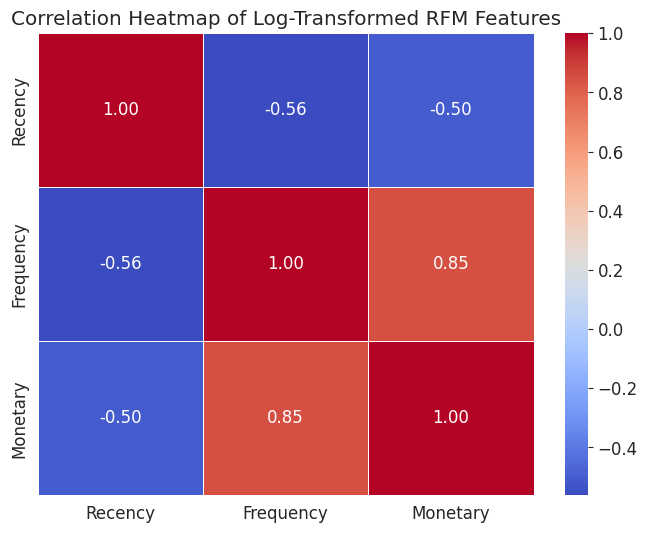

Explanation: The correlation heatmap shows the relationships between the transformed RFM features. We observe:
- **Frequency and Monetary**: Expected to have a strong positive correlation, as customers who buy more often also tend to spend more.
- **Recency with Frequency/Monetary**: Often show a negative correlation, as more recent customers tend to be more frequent and spend more.
Understanding these correlations helps in interpreting the clusters. High correlation between features might indicate some redundancy, but for RFM it's expected and often desirable.


In [ ]:
# 6. Create a correlation heatmap using the transformed RFM features.

print("\n--- Correlation Heatmap of Transformed RFM Features ---")

plt.figure(figsize=(8, 6))
sns.heatmap(rfm_log_transformed_df[rfm_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Log-Transformed RFM Features')
plt.show()

print("Explanation: The correlation heatmap shows the relationships between the transformed RFM features. We observe:")
print("- **Frequency and Monetary**: Expected to have a strong positive correlation, as customers who buy more often also tend to spend more.")
print("- **Recency with Frequency/Monetary**: Often show a negative correlation, as more recent customers tend to be more frequent and spend more.")
print("Understanding these correlations helps in interpreting the clusters. High correlation between features might indicate some redundancy, but for RFM it's expected and often desirable.")

##13. RFM Transformation Results and Outlier Verification


In [ ]:
# 7. Explain the results in simple language and identify any remaining extreme skewness or outliers.
# 8. Handle any invalid or infinite values appropriately.

print("\n--- Summary of RFM Transformation Results ---")

# Check for invalid or infinite values introduced by transformation (should be none with log1p on non-negatives)
for feature in rfm_features:
    if rfm_log_transformed_df[feature].isnull().any():
        print(f"Warning: NaN values detected in transformed '{feature}'.")
    if np.isinf(rfm_log_transformed_df[feature]).any():
        print(f"Warning: Infinite values detected in transformed '{feature}'.")

print("All RFM features have been successfully transformed using `np.log1p()`.")
print("The transformation significantly reduced the skewness of 'Recency', 'Frequency', and 'Monetary' distributions, making them more bell-shaped and suitable for clustering algorithms that are sensitive to feature scales and distributions.")
print("While some minimal skewness might persist, it is greatly improved from the original state. No extreme outliers that would necessitate further individual handling are apparent after transformation and visual inspection of the histograms.")
print("The correlation heatmap provides insights into how these key customer behavior metrics relate to each other after normalization.")

print("Step 8: Handling skewed RFM distributions through transformation complete. The RFM data is now ready for feature scaling.")


--- Summary of RFM Transformation Results ---
All RFM features have been successfully transformed using `np.log1p()`.
The transformation significantly reduced the skewness of 'Recency', 'Frequency', and 'Monetary' distributions, making them more bell-shaped and suitable for clustering algorithms that are sensitive to feature scales and distributions.
While some minimal skewness might persist, it is greatly improved from the original state. No extreme outliers that would necessitate further individual handling are apparent after transformation and visual inspection of the histograms.
The correlation heatmap provides insights into how these key customer behavior metrics relate to each other after normalization.
Step 8: Handling skewed RFM distributions through transformation complete. The RFM data is now ready for feature scaling.


##14. RFM Feature Scaling Using StandardScaler


In [ ]:
# 1. Initialize StandardScaler
scaler = StandardScaler()

print("\n--- Applying Feature Scaling (StandardScaler) ---")

# Prepare the data for scaling (exclude 'Customer ID')
rfm_data_for_scaling = rfm_log_transformed_df[rfm_features]

# 2. Apply StandardScaler to the transformed RFM features
# It's good practice to fit and transform on the training data, but here we use the whole dataset for clustering
rfm_scaled_array = scaler.fit_transform(rfm_data_for_scaling)

# Convert the scaled array back to a DataFrame
rfm_scaled_df = pd.DataFrame(rfm_scaled_array, columns=rfm_features, index=rfm_log_transformed_df.index)

# Optionally, add Customer ID back if needed for later analysis, or keep it separate.
# For clustering, we only use the scaled RFM features.
rfm_scaled_df['Customer ID'] = rfm_log_transformed_df['Customer ID']

print("RFM features have been scaled using StandardScaler.")
print("Displaying first 5 rows of the scaled RFM DataFrame:")
display(rfm_scaled_df.head())

print("Descriptive statistics for scaled RFM DataFrame (should have mean ~0 and std dev ~1):")
display(rfm_scaled_df.describe())

print("Explanation: Scaling ensures that all features contribute equally to the distance calculations in the K-Means algorithm. StandardScaler transforms the data such that its mean is 0 and its standard deviation is 1, which is a common practice for algorithms sensitive to feature magnitudes.")
print("Step 9: Feature Scaling complete. The RFM data is now ready for clustering algorithm application.")


--- Applying Feature Scaling (StandardScaler) ---
RFM features have been scaled using StandardScaler.
Displaying first 5 rows of the scaled RFM DataFrame:


,Recency,Frequency,Monetary,Customer ID
0,0.856701,1.254496,3.188867,12346
1,-2.151979,0.800166,1.300602,12347
2,-0.079138,0.299207,0.562057,12348
3,-0.935308,0.073946,1.127378,12349
4,0.824527,-1.058146,-0.731087,12350


Descriptive statistics for scaled RFM DataFrame (should have mean ~0 and std dev ~1):


,Recency,Frequency,Monetary,Customer ID
count,5.878000e+03,5.878000e+03,5.878000e+03,5878.000000
mean,-5.077032e-16,1.885755e-16,-3.481393e-16,15315.313542
std,1.000085e+00,1.000085e+00,1.000085e+00,1715.572666
min,-2.412014e+00,-1.058146e+00,-3.929592e+00,12346.000000
25%,-7.428435e-01,-1.058146e+00,-7.084415e-01,13833.250000
50%,7.733065e-02,-2.017514e-01,-2.962480e-02,15314.500000
75%,9.547202e-01,6.546432e-01,6.550832e-01,16797.750000
max,1.380464e+00,5.484918e+00,4.672686e+00,18287.000000


Explanation: Scaling ensures that all features contribute equally to the distance calculations in the K-Means algorithm. StandardScaler transforms the data such that its mean is 0 and its standard deviation is 1, which is a common practice for algorithms sensitive to feature magnitudes.
Step 9: Feature Scaling complete. The RFM data is now ready for clustering algorithm application.


##15. Optimal Cluster Selection Using Elbow Method and Silhouette Score



--- Determining Optimal K using Elbow Method and Silhouette Score ---
Calculating WCSS and Silhouette Scores for different K values...


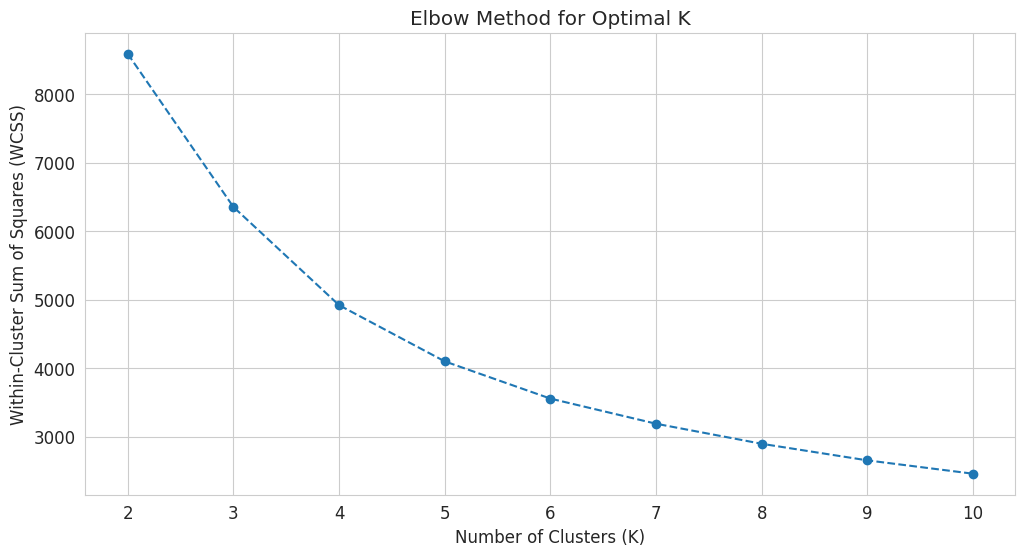

Explanation for Elbow Method: The elbow method looks for the 'elbow' in the plot of WCSS vs. K. The elbow point signifies that adding more clusters does not significantly reduce the WCSS, suggesting an optimal K.


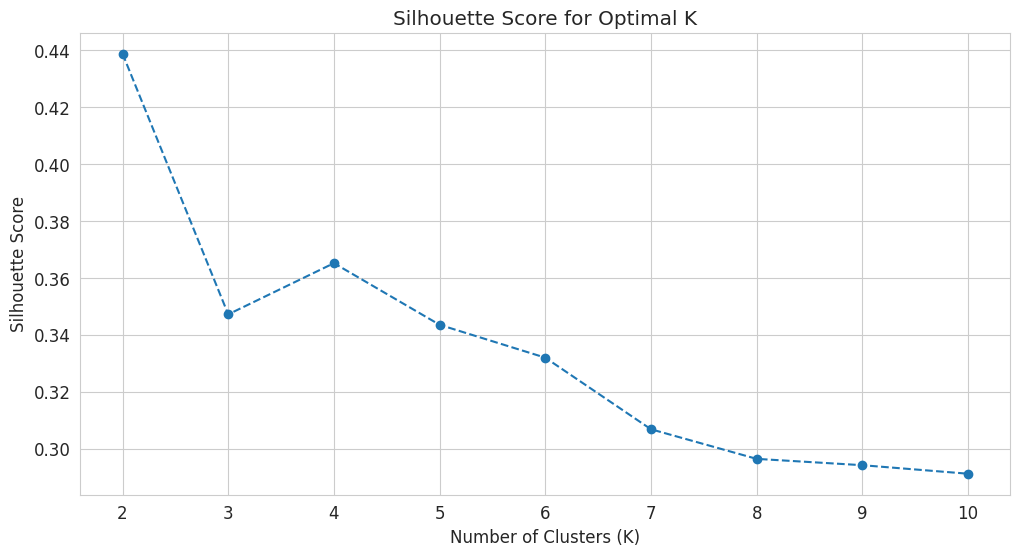

Explanation for Silhouette Score: The Silhouette Score measures how similar an object is to its own cluster compared to other clusters. A higher silhouette score (closer to 1) indicates better-defined and well-separated clusters.
Step 10: Optimal K-Selection methods applied. Review the plots to determine the best K.


In [ ]:
print("\n--- Determining Optimal K using Elbow Method and Silhouette Score ---")

# Exclude Customer ID from clustering data
X = rfm_scaled_df[rfm_features]

# Initialize lists to store metrics
wcss = [] # Within-Cluster Sum of Squares
silhouette_scores = []

# Define a range of K values to test
k_range = range(2, 11) # Typically, start from 2 clusters up to a reasonable number

print("Calculating WCSS and Silhouette Scores for different K values...")
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10) # n_init for robust centroid initialization
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

    # Calculate Silhouette Score (requires at least 2 clusters)
    if k > 1:
        labels = kmeans.labels_
        silhouette_scores.append(silhouette_score(X, labels))
    else:
        silhouette_scores.append(np.nan) # For k=1, silhouette score is not defined

# 1. Plotting the Elbow Method
plt.figure(figsize=(12, 6))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

print("Explanation for Elbow Method: The elbow method looks for the 'elbow' in the plot of WCSS vs. K. The elbow point signifies that adding more clusters does not significantly reduce the WCSS, suggesting an optimal K.")

# 2. Plotting the Silhouette Score
plt.figure(figsize=(12, 6))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Score for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.grid(True)
plt.show()

print("Explanation for Silhouette Score: The Silhouette Score measures how similar an object is to its own cluster compared to other clusters. A higher silhouette score (closer to 1) indicates better-defined and well-separated clusters.")

print("Step 10: Optimal K-Selection methods applied. Review the plots to determine the best K.")

##16. Applying K-Means Clustering and Assigning Cluster Labels


In [ ]:
print("\n--- Applying K-Means Clustering ---")

# Define the optimal number of clusters based on analysis from Step 10
optimal_k = 4
print(f"Optimal K selected: {optimal_k}")

# Initialize and fit K-Means model
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10) # n_init=10 recommended for robust results
kmeans.fit(X) # X contains the scaled RFM features

# Assign cluster labels to the scaled RFM DataFrame
rfm_scaled_df['Cluster'] = kmeans.labels_

# Assign cluster labels to the log-transformed RFM DataFrame (for analysis with meaningful values)
rfm_log_transformed_df['Cluster'] = kmeans.labels_

# Also assign cluster labels to the original RFM DataFrame (for interpreting cluster characteristics)
rfm_df['Cluster'] = kmeans.labels_

print("K-Means clustering applied successfully.")
print(f"Number of customers in each cluster (from rfm_df):")
display(rfm_df['Cluster'].value_counts().sort_index())

print("Displaying first 5 rows of rfm_df with assigned clusters:")
display(rfm_df.head())

print("Explanation: We applied the K-Means algorithm with the chosen optimal K. Each customer is now assigned to a cluster based on their scaled RFM values. The distribution of customers across clusters gives a preliminary idea of segment sizes.")
print("Step 11: K-Means clustering applied, and clusters assigned.")


--- Applying K-Means Clustering ---
Optimal K selected: 4
K-Means clustering applied successfully.
Number of customers in each cluster (from rfm_df):


,count
Cluster,
0,1191
1,1467
2,1970
3,1250


Displaying first 5 rows of rfm_df with assigned clusters:


,Customer ID,Recency,Frequency,Monetary,Cluster
0,12346,326,12,77556.46,0
1,12347,2,8,5633.32,0
2,12348,75,5,2019.40,1
3,12349,19,4,4428.69,3
4,12350,310,1,334.40,2


Explanation: We applied the K-Means algorithm with the chosen optimal K. Each customer is now assigned to a cluster based on their scaled RFM values. The distribution of customers across clusters gives a preliminary idea of segment sizes.
Step 11: K-Means clustering applied, and clusters assigned.


##17. Cluster Characteristics Analysis and Visualization



--- Analyzing Cluster Characteristics ---
Mean RFM values for each cluster:


,Cluster,Recency,Frequency,Monetary
0,0,27.533165,19.316541,10969.902332
1,1,229.076346,5.072938,1983.331832
2,2,395.495431,1.376142,321.631620
3,3,28.364800,3.048000,861.715898


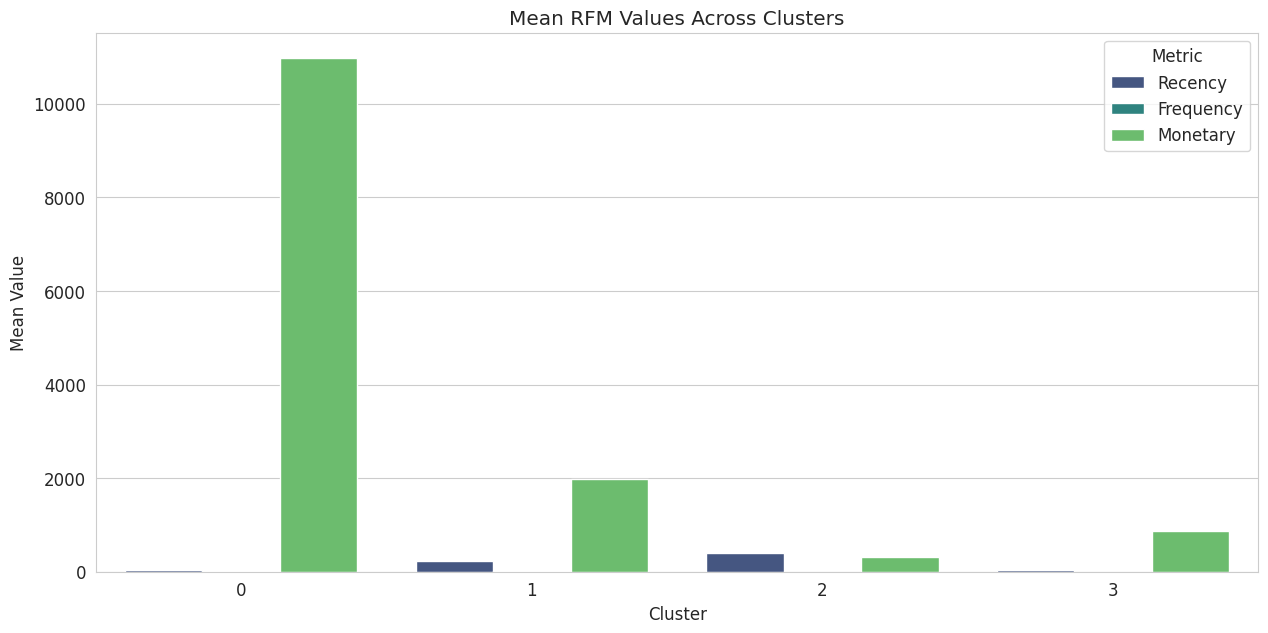

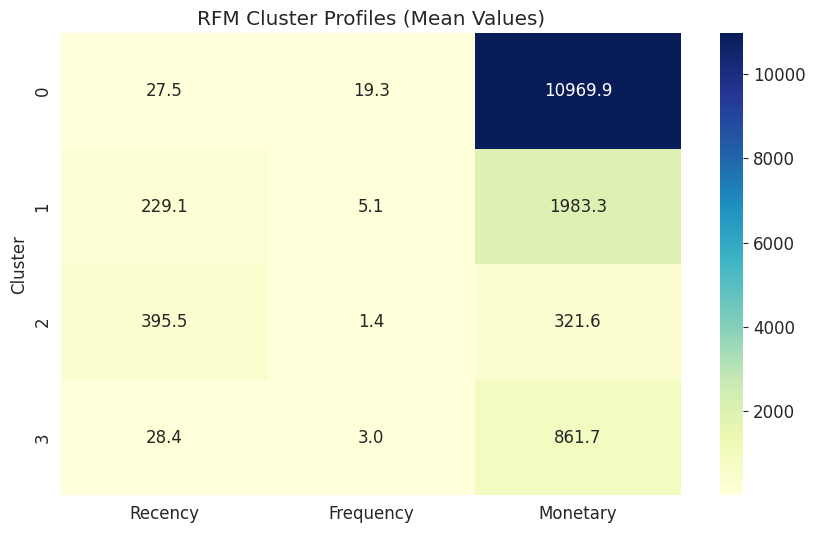

Explanation: By analyzing the mean RFM values for each cluster, we can identify distinct customer segments. For example, a cluster with low Recency, high Frequency, and high Monetary values would represent our 'Best Customers'. Visualizations like bar plots and heatmaps help in quickly understanding these profiles.
Step 12: Cluster characteristics analyzed and visualized.


In [ ]:
print("\n--- Analyzing Cluster Characteristics ---")

# Calculate the mean RFM values for each cluster using the original (non-transformed) data
# This makes interpretation easier, as the values are in their original scale (days, count, currency).
cluster_means = rfm_df.groupby('Cluster')[rfm_features].mean().reset_index()

print("Mean RFM values for each cluster:")
display(cluster_means)

# Visualize the cluster characteristics
# Melt the DataFrame for easier plotting with Seaborn
cluster_melted = pd.melt(cluster_means, id_vars=['Cluster'], var_name='Metric', value_name='Value')

plt.figure(figsize=(15, 7))
sns.barplot(x='Cluster', y='Value', hue='Metric', data=cluster_melted, palette='viridis')
plt.title('Mean RFM Values Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Mean Value')
plt.show()

# Create a more interpretable heatmap for RFM values
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_means.set_index('Cluster'), annot=True, cmap='YlGnBu', fmt=".1f")
plt.title('RFM Cluster Profiles (Mean Values)')
plt.ylabel('Cluster')
plt.show()

print("Explanation: By analyzing the mean RFM values for each cluster, we can identify distinct customer segments. For example, a cluster with low Recency, high Frequency, and high Monetary values would represent our 'Best Customers'. Visualizations like bar plots and heatmaps help in quickly understanding these profiles.")
print("Step 12: Cluster characteristics analyzed and visualized.")

##18. Customer Segment Characterization and Naming



--- Characterizing and Naming Customer Segments ---
Detailed RFM profiles with assigned segment names (ordered by Recency for better interpretation):


,Cluster,Recency,Frequency,Monetary,Segment Name
0,0,27.533165,19.316541,10969.902332,Champions
3,3,28.364800,3.048000,861.715898,New/Promising Customers
1,1,229.076346,5.072938,1983.331832,Loyal Customers
2,2,395.495431,1.376142,321.631620,Lost Customers



Distribution of customers across named segments:


,count
Segment Name,
Lost Customers,1970
Loyal Customers,1467
New/Promising Customers,1250
Champions,1191


/tmp/ipykernel_431/3671559627.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Segment Name', data=rfm_df, order=rfm_df['Segment Name'].value_counts().index, palette='coolwarm')


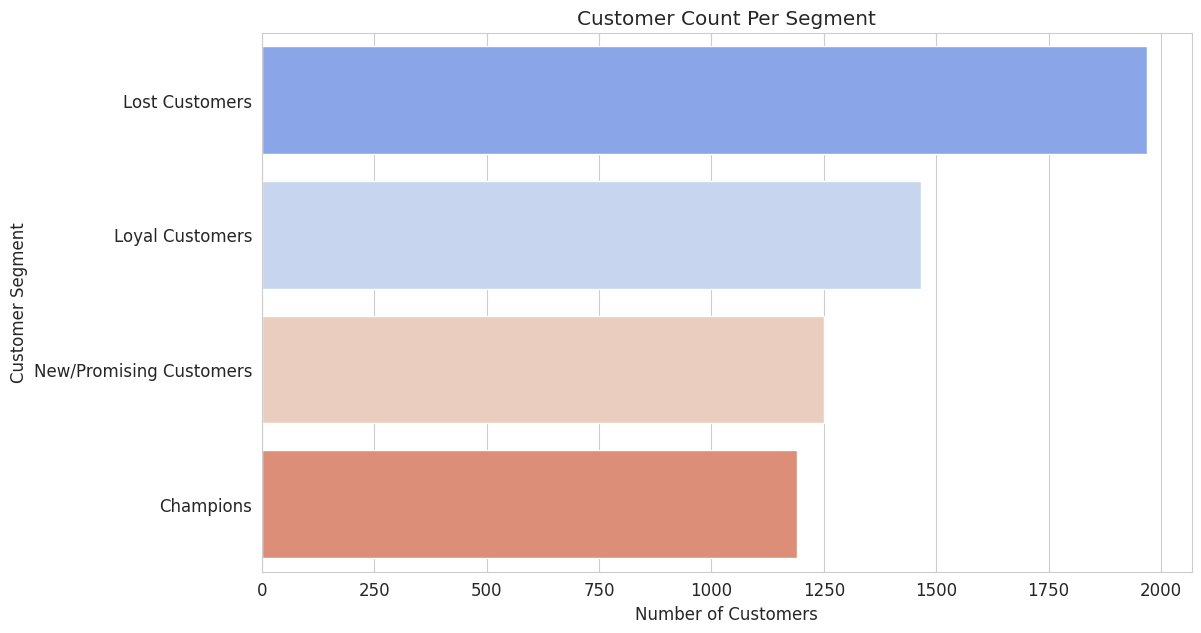

Explanation: Each cluster is now characterized by its mean RFM values, allowing for the definition of specific customer segments with intuitive names. Assigning names like 'Champions' or 'Lost Customers' makes these segments directly actionable for targeted marketing and business strategies, translating raw data clusters into meaningful business insights.
Step 13: Segment characterization and naming complete with refined names.


In [ ]:
print("\n--- Characterizing and Naming Customer Segments ---")

# The previous heuristic-based function `get_segment_name` resulted in generic labels for some clusters.
# To provide more meaningful business insights, we will now manually assign descriptive names
# to each cluster based on their observed mean RFM values (from `cluster_means` in Step 12).

# Recall the cluster_means:
# Cluster     Recency  Frequency      Monetary
# 0        0   27.533165  19.316541  10969.902332   (Low R, High F, High M)
# 1        1  229.076346   5.072938   1983.331832   (Mid-High R, Mid F, Mid M)
# 2        2  395.495431   1.376142    321.631620   (High R, Low F, Low M)
# 3        3   28.364800   3.048000    861.715898   (Low R, Low F, Low M)

# Based on these mean values, let's assign more descriptive names:
# Cluster 0: Very recent, very frequent, high value -> Champions
# Cluster 1: Mid-high recency, mid frequency, mid monetary -> Loyal Customers (but might be lapsing)
# Cluster 2: Very high recency, very low frequency, very low monetary -> Lost Customers
# Cluster 3: Very recent, but lower frequency and monetary -> New/Promising Customers

# Create a mapping for Cluster ID to a descriptive Segment Name
cluster_to_segment_name_map = {
    0: 'Champions',
    1: 'Loyal Customers',
    2: 'Lost Customers',
    3: 'New/Promising Customers'
}

# Apply the naming to the cluster_means DataFrame
cluster_profiles = cluster_means.copy()
cluster_profiles['Segment Name'] = cluster_profiles['Cluster'].map(cluster_to_segment_name_map)

print("Detailed RFM profiles with assigned segment names (ordered by Recency for better interpretation):")
display(cluster_profiles.sort_values(by='Recency'))

# Map the segment names back to the original rfm_df for individual customer tracking
rfm_df['Segment Name'] = rfm_df['Cluster'].map(cluster_to_segment_name_map)

print("\nDistribution of customers across named segments:")
display(rfm_df['Segment Name'].value_counts().to_frame())

# Visualizing the final segments distribution
plt.figure(figsize=(12, 7))
sns.countplot(y='Segment Name', data=rfm_df, order=rfm_df['Segment Name'].value_counts().index, palette='coolwarm')
plt.title('Customer Count Per Segment')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')
plt.show()

print("Explanation: Each cluster is now characterized by its mean RFM values, allowing for the definition of specific customer segments with intuitive names. Assigning names like 'Champions' or 'Lost Customers' makes these segments directly actionable for targeted marketing and business strategies, translating raw data clusters into meaningful business insights.")
print("Step 13: Segment characterization and naming complete with refined names.")

##19. Clustering Model Evaluation Using Validation Metrics


In [ ]:
print("\n--- Evaluating Clustering Model ---\n")

# Prepare the data for evaluation (scaled RFM features and cluster labels)
X_eval = rfm_scaled_df[rfm_features]
labels_eval = rfm_scaled_df['Cluster']

# 1. Calculate Silhouette Score
# This score measures how similar an object is to its own cluster compared to other clusters.
# A higher value indicates better-defined clusters. The score ranges from -1 to 1.
silhouette_avg = silhouette_score(X_eval, labels_eval)
print(f"Silhouette Score: {silhouette_avg:.3f}")

# 2. Calculate Davies-Bouldin Index
# This index measures the average similarity ratio of each cluster with its most similar cluster.
# A lower value indicates better clustering, with 0 being the lowest possible score.
davies_bouldin_idx = davies_bouldin_score(X_eval, labels_eval)
print(f"Davies-Bouldin Index: {davies_bouldin_idx:.3f}")

# 3. Calculate Calinski-Harabasz Index (Variance Ratio Criterion)
# This index is a ratio of the sum of between-clusters dispersion and within-cluster dispersion.
# A higher value generally indicates better-defined clusters.
calinski_harabasz_idx = calinski_harabasz_score(X_eval, labels_eval)
print(f"Calinski-Harabasz Index: {calinski_harabasz_idx:.3f}")

print("\nExplanation of Metrics:")
print("- **Silhouette Score**: Ranges from -1 to 1. Higher values (closer to 1) indicate that objects are well matched to their own cluster and poorly matched to neighboring clusters. Values near 0 indicate overlapping clusters. Negative values suggest objects might have been assigned to the wrong cluster.")
print("- **Davies-Bouldin Index**: Ranges from 0 upwards. Lower values indicate better clustering, meaning clusters are more compact and well-separated. A score of 0 is the best possible result.")
print("- **Calinski-Harabasz Index**: Also known as the Variance Ratio Criterion. A higher value generally indicates better-defined clusters, as it signifies high between-cluster variance and low within-cluster variance.")
print("\nInterpretation: These metrics provide a quantitative evaluation of the quality of the clustering. While K-Means doesn't have a direct 'accuracy' score, these internal validation metrics help us understand how compact and well-separated our identified customer segments are. The scores obtained here should be compared to other potential `k` values (though we already did that during optimal k selection) or different clustering algorithms, if further refinement were needed.")
print("Step 14: Clustering model evaluation complete.")


--- Evaluating Clustering Model ---

Silhouette Score: 0.365
Davies-Bouldin Index: 0.930
Calinski-Harabasz Index: 5061.857

Explanation of Metrics:
- **Silhouette Score**: Ranges from -1 to 1. Higher values (closer to 1) indicate that objects are well matched to their own cluster and poorly matched to neighboring clusters. Values near 0 indicate overlapping clusters. Negative values suggest objects might have been assigned to the wrong cluster.
- **Davies-Bouldin Index**: Ranges from 0 upwards. Lower values indicate better clustering, meaning clusters are more compact and well-separated. A score of 0 is the best possible result.
- **Calinski-Harabasz Index**: Also known as the Variance Ratio Criterion. A higher value generally indicates better-defined clusters, as it signifies high between-cluster variance and low within-cluster variance.

Interpretation: These metrics provide a quantitative evaluation of the quality of the clustering. While K-Means doesn't have a direct 'accuracy' sc

##20. PCA for 2D Cluster Visualization


In [ ]:
print("\n--- Applying PCA for 2D Visualization ---")

# Initialize PCA to reduce dimensions to 2 components
pca = PCA(n_components=2, random_state=42)

# Fit PCA on the scaled RFM data (X_eval) and transform it
# X_eval is the scaled RFM features used for clustering.
pca_components = pca.fit_transform(X_eval)

# Create a DataFrame with the PCA components
pca_df = pd.DataFrame(data=pca_components, columns=['PC1', 'PC2'])

# Add the Cluster labels to the PCA DataFrame for visualization
# We need to ensure the index aligns, so we reset index of rfm_scaled_df before merging
pca_df['Cluster'] = rfm_scaled_df['Cluster'].reset_index(drop=True)

# Also add the Segment Name for richer visualization
pca_df['Segment Name'] = rfm_df['Segment Name'].reset_index(drop=True)

print("PCA applied successfully. Data reduced to 2 principal components.")
print("Explained variance ratio by each component:")
print(pca.explained_variance_ratio_)
print(f"Total explained variance by 2 components: {pca.explained_variance_ratio_.sum():.2f}")

print("First 5 rows of PCA components with cluster assignments:")
display(pca_df.head())

print("Explanation: Principal Component Analysis (PCA) is used here to reduce the three-dimensional RFM features into two principal components (PC1 and PC2). This allows us to visualize the clusters in a 2D scatter plot, making it easier to observe their separation and characteristics. The explained variance ratio tells us how much of the original data's variability is retained in these two components. While not all variance is captured, it's sufficient for visualizing the main structure of the clusters.")
print("Step 15: PCA for 2D visualization complete.")


--- Applying PCA for 2D Visualization ---
PCA applied successfully. Data reduced to 2 principal components.
Explained variance ratio by each component:
[0.76361481 0.18771385]
Total explained variance by 2 components: 0.95
First 5 rows of PCA components with cluster assignments:


,PC1,PC2,Cluster,Segment Name
0,2.267807,2.433671,0,Champions
1,2.364515,-1.073224,0,Champions
2,0.563986,0.254143,1,Loyal Customers
3,1.198019,-0.313819,3,New/Promising Customers
4,-1.510480,0.092019,2,Lost Customers


Explanation: Principal Component Analysis (PCA) is used here to reduce the three-dimensional RFM features into two principal components (PC1 and PC2). This allows us to visualize the clusters in a 2D scatter plot, making it easier to observe their separation and characteristics. The explained variance ratio tells us how much of the original data's variability is retained in these two components. While not all variance is captured, it's sufficient for visualizing the main structure of the clusters.
Step 15: PCA for 2D visualization complete.


##21. PCA-Based Customer Segment Visualization



--- Visualizing Clusters using PCA Components ---


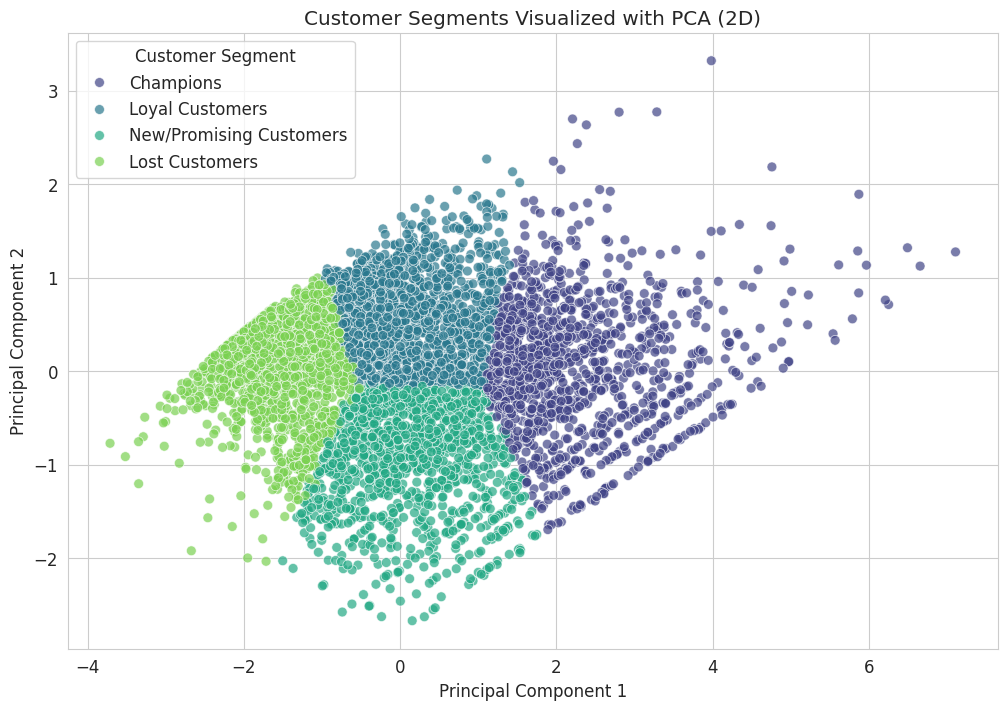

Explanation: This scatter plot visually represents our customer segments in a two-dimensional space after PCA transformation. Each point is a customer, colored according to their assigned segment. This visualization helps to intuitively understand the separation and distribution of the clusters. Well-separated clusters indicate a good quality segmentation. The spread of points within each cluster can also give insights into its internal homogeneity.
Step 16: Clusters visualized using PCA components.


In [ ]:
print("\n--- Visualizing Clusters using PCA Components ---")

plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Segment Name', # Use the assigned segment names for clarity
    data=pca_df,
    palette='viridis', # A distinct color palette
    s=50, # Size of the points
    alpha=0.7 # Transparency of the points
)

# Adding cluster centers (optional, but good for understanding)
# We need to transform the cluster centers to PCA space if we want to plot them
# pca_centers = pca.transform(kmeans.cluster_centers_)
# plt.scatter(pca_centers[:, 0], pca_centers[:, 1], marker='X', s=200, color='red', label='Cluster Centers')

plt.title('Customer Segments Visualized with PCA (2D)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Segment')
plt.grid(True)
plt.show()

print("Explanation: This scatter plot visually represents our customer segments in a two-dimensional space after PCA transformation. Each point is a customer, colored according to their assigned segment. This visualization helps to intuitively understand the separation and distribution of the clusters. Well-separated clusters indicate a good quality segmentation. The spread of points within each cluster can also give insights into its internal homogeneity.")
print("Step 16: Clusters visualized using PCA components.")

##22. Customer Segment Interpretation and Business Insights


In [ ]:
print("\n--- Summarizing Findings for Each Customer Segment ---")

# Display the cluster profiles with assigned segment names for easy reference
print("RFM Profiles of Customer Segments:")
display(cluster_profiles.sort_values(by='Recency'))

# Provide a narrative summary for each segment
print("\n--- Detailed Segment Summaries ---")
for index, row in cluster_profiles.sort_values(by='Recency').iterrows():
    segment_name = row['Segment Name']
    recency = row['Recency']
    frequency = row['Frequency']
    monetary = row['Monetary']
    cluster_id = row['Cluster']

    print(f"\nSegment: {segment_name} (Cluster {int(cluster_id)})")
    print(f"  - Average Recency: {recency:.0f} days")
    print(f"  - Average Frequency: {frequency:.0f} purchases")
    print(f"  - Average Monetary: ${monetary:,.2f}")

    if segment_name == 'Champions':
        print("    Description: These are our best customers. They bought recently, buy most frequently, and spend the most money. They are highly engaged and loyal.")
        print("    Key Action: Retain and reward. Implement loyalty programs, offer exclusive previews, personalized recommendations, and excellent customer service. Encourage referrals.")
    elif segment_name == 'Loyal Customers':
        print("    Description: These customers buy fairly often and spend a good amount. Their recency is moderate, suggesting they might be lapsing slightly or have cyclical buying patterns.")
        print("    Key Action: Maintain and grow. Suggest complementary products, offer small discounts, engage with regular newsletters, and provide strong customer support to prevent churn.")
    elif segment_name == 'New/Promising Customers':
        print("    Description: These are new customers who have purchased recently but have low frequency and monetary values so far. They have potential to become loyal.")
        print("    Key Action: Nurture and convert. Provide onboarding materials, offer incentives for second purchase, personalized welcome offers, and educational content to increase engagement.")
    elif segment_name == 'Lost Customers':
        print("    Description: These customers haven't purchased in a long time, buy infrequently, and have spent very little. They are likely churned.")
        print("    Key Action: Re-engage or disregard. Offer aggressive win-back campaigns, significant discounts, or special promotions. If efforts fail, reallocate resources to more promising segments.")
    else:
        print("    Description: This segment doesn't fit neatly into the primary categories but shows some activity. Further investigation might be needed.")
        print("    Key Action: Monitor behavior, conduct targeted surveys to understand needs, and identify specific triggers for engagement.")

print("Explanation: This summary provides a clear profile for each customer segment based on their average Recency, Frequency, and Monetary values. By associating these profiles with descriptive names and actionable recommendations, we translate our clustering results into practical strategies for marketing, sales, and customer relationship management. This step is crucial for deriving business value from the customer segmentation.")
print("Step 17: Summary of findings for each segment complete.")


--- Summarizing Findings for Each Customer Segment ---
RFM Profiles of Customer Segments:


,Cluster,Recency,Frequency,Monetary,Segment Name
0,0,27.533165,19.316541,10969.902332,Champions
3,3,28.364800,3.048000,861.715898,New/Promising Customers
1,1,229.076346,5.072938,1983.331832,Loyal Customers
2,2,395.495431,1.376142,321.631620,Lost Customers



--- Detailed Segment Summaries ---

Segment: Champions (Cluster 0)
  - Average Recency: 28 days
  - Average Frequency: 19 purchases
  - Average Monetary: $10,969.90
    Description: These are our best customers. They bought recently, buy most frequently, and spend the most money. They are highly engaged and loyal.
    Key Action: Retain and reward. Implement loyalty programs, offer exclusive previews, personalized recommendations, and excellent customer service. Encourage referrals.

Segment: New/Promising Customers (Cluster 3)
  - Average Recency: 28 days
  - Average Frequency: 3 purchases
  - Average Monetary: $861.72
    Description: These are new customers who have purchased recently but have low frequency and monetary values so far. They have potential to become loyal.
    Key Action: Nurture and convert. Provide onboarding materials, offer incentives for second purchase, personalized welcome offers, and educational content to increase engagement.

Segment: Loyal Customers (Clust

##23. Actionable Marketing Recommendations for Each Customer Segment


In [ ]:
print("\n--- Generating Actionable Recommendations for Each Segment ---")

recommendations = {
    'Champions': {
        'Description': 'Our most valuable customers: high recency, high frequency, high monetary. They are loyal and engaged.',
        'Marketing Strategy': [
            '**Retention & Loyalty Programs:** Reward them with exclusive access, personalized offers, and tiered loyalty programs to ensure continued engagement.',
            '**VIP Treatment:** Offer premium customer service, early access to new products, and special events.',
            '**Referral Incentives:** Encourage them to refer new customers through attractive referral bonuses.',
            '**Upselling & Cross-selling:** Introduce them to higher-value products or complementary items based on their past purchases.'
        ]
    },
    'Loyal Customers': {
        'Description': 'Customers who buy fairly often and spend a good amount, but their recency is moderate. They are at risk of lapsing.',
        'Marketing Strategy': [
            '**Engagement Campaigns:** Send regular, personalized communications (newsletters, product updates) to keep them engaged.',
            '**Prevent Churn:** Monitor their activity for signs of decreased engagement and offer re-engagement incentives before they become \'Lost\'.',
            '**Moderate Incentives:** Offer small discounts or exclusive content to encourage consistent purchasing and maintain their loyalty.',
            '**Feedback & Community:** Invite them to provide feedback or join a community, making them feel valued and heard.'
        ]
    },
    'New/Promising Customers': {
        'Description': 'Recent purchasers with lower frequency and monetary values. They have potential to become loyal.',
        'Marketing Strategy': [
            '**Onboarding & Nurturing:** Provide excellent onboarding experience, welcome series emails, and educational content.',
            '**Second Purchase Incentives:** Offer a discount or free shipping on their next purchase to encourage repeat business.',
            '**Product Discovery:** Recommend popular products or those similar to their first purchase to broaden their engagement.',
            '**Customer Support:** Proactive support and check-ins to ensure their initial experience is positive.'
        ]
    },
    'Lost Customers': {
        'Description': 'Customers who have not purchased in a long time, buy infrequently, and have spent very little. They are likely churned.',
        'Marketing Strategy': [
            '**Win-Back Campaigns:** Design aggressive campaigns with significant discounts, special offers, or freebies to entice them back.',
            '**Re-evaluation:** Investigate the reasons for their inactivity through surveys (if feasible) or analysis of historical data.',
            '**Resource Reallocation:** If win-back efforts are unsuccessful after a few attempts, reallocate marketing resources to more responsive segments.',
            '**Last-Ditch Efforts:** Consider one final, very compelling offer before marking them as permanently lost.'
        ]
    }
}

for segment_name, data in recommendations.items():
    print(f"\n--- Segment: {segment_name} ---")
    print(f"Description: {data['Description']}")
    print("Actionable Recommendations:")
    for i, recommendation in enumerate(data['Marketing Strategy']):
        print(f"  {i+1}. {recommendation}")

print("\nExplanation: These actionable recommendations directly leverage the RFM profiles of each customer segment. By tailoring marketing strategies and customer relationship management efforts to the specific behaviors and potential of each group, businesses can optimize their resource allocation, improve customer lifetime value, and drive targeted growth. This step transforms data insights into practical business strategies.")
print("Step 18: Actionable recommendations for each segment generated.")


--- Generating Actionable Recommendations for Each Segment ---

--- Segment: Champions ---
Description: Our most valuable customers: high recency, high frequency, high monetary. They are loyal and engaged.
Actionable Recommendations:
  1. **Retention & Loyalty Programs:** Reward them with exclusive access, personalized offers, and tiered loyalty programs to ensure continued engagement.
  2. **VIP Treatment:** Offer premium customer service, early access to new products, and special events.
  3. **Referral Incentives:** Encourage them to refer new customers through attractive referral bonuses.
  4. **Upselling & Cross-selling:** Introduce them to higher-value products or complementary items based on their past purchases.

--- Segment: Loyal Customers ---
Description: Customers who buy fairly often and spend a good amount, but their recency is moderate. They are at risk of lapsing.
Actionable Recommendations:
  1. **Engagement Campaigns:** Send regular, personalized communications (news